# Grouped genome browser tracks (ArchR `plotBrowserTrack`)

`epi.pl.plot_browser_track` ports ArchR's `plotBrowserTrack`: one normalised
pseudo-bulk ATAC track per cell group, plus peak, loop (co-accessibility /
peak-to-gene) and gene tracks, with the same layout and colours as ArchR.

Coverage is read directly from tabix-indexed fragment files, so you do not
need BigWigs. The numbers match ArchR 1.0.3 tile for tile (see the parity
section at the end).

## How the coverage is computed

This is ArchR's `.groupRegionSumArrows`, reproduced exactly:

1. Groups with fewer than `min_cells` cells are dropped. Groups larger than
   `max_cells` are subsampled with R's `sample()`. Epione reimplements R's RNG,
   so `seed=1` picks the same cells as ArchR after `set.seed(1)`.
   ArchR switches R to `L'Ecuyer-CMRG` whenever `addArchRThreads(threads > 1)`;
   this is `rng="archr"`, the default.
2. The window is cut into `tile_size` bp tiles. For each cell and tile, the
   value is 1 if at least one fragment **starts** in that tile. ArchR 1.0.3
   computes both of its tile indices from the fragment start, so ends are not
   counted. Pass `count_ends=True` to also count the end tile.
3. Per group, the cell counts are summed. They are then scaled by
   `1e4 / sum(ReadsInTSS)` over the group's cells (`norm_method`).
4. For plotting, the signal is clipped at its 0.999 quantile, and all groups
   share one y-axis.

In [1]:
%matplotlib inline
import pathlib
import numpy as np
import pandas as pd
import anndata as ad
import matplotlib as mpl
import matplotlib.pyplot as plt
import epione as epi

mpl.rcParams['figure.dpi'] = 90
FIXTURE = pathlib.Path('/scratch/users/steorra/analysis/25_epione/epione_dev/fixture')
FRAG_DIR = pathlib.Path('/scratch/users/steorra/data/archr_heme/HemeFragments')
ARCHR_REF = pathlib.Path('/scratch/users/steorra/analysis/25_epione/epione_dev/work/browser-track/ref')

## Data

We use the ArchR hematopoiesis tutorial data (`getTutorialData("Hematopoiesis")`):
3 samples (BMMC, CD34+ BMMC, PBMC) and 10,660 cells. Cell metadata
(`Sample`, `Clusters`, `ReadsInTSS`, ...) comes from the ArchR project's
`cellColData`. Cell names follow ArchR's `Sample#barcode` convention, which
is how cells are matched to the per-sample fragment files.

In [2]:
T = FIXTURE / 'tables'
cells = pd.read_csv(T / 'cells.tsv', sep='\t', index_col=0)
adata = ad.AnnData(obs=cells)

genes = pd.read_csv(T / 'genes_hg19.tsv', sep='\t')   # chrom/start/end/strand/symbol
exons = pd.read_csv(T / 'exons_hg19.tsv', sep='\t')
peaks = pd.read_csv(T / 'peaks.tsv', sep='\t')        # ArchR peak set
fragments = {s: str(FRAG_DIR / f'{s}.fragments.tsv.gz')
             for s in ['scATAC_BMMC_R1', 'scATAC_CD34_BMMC_R1', 'scATAC_PBMC_R1']}

print(adata)
adata.obs[['Sample', 'Clusters', 'ReadsInTSS', 'nFrags']].head()

AnnData object with n_obs × n_vars = 10660 × 0
    obs: 'Sample', 'TSSEnrichment', 'ReadsInTSS', 'ReadsInPromoter', 'ReadsInBlacklist', 'PromoterRatio', 'PassQC', 'NucleosomeRatio', 'nMultiFrags', 'nMonoFrags', 'nFrags', 'nDiFrags', 'BlacklistRatio', 'Clusters', 'ReadsInPeaks', 'FRIP', 'UMAP1', 'UMAP2'


,Sample,Clusters,ReadsInTSS,nFrags
barcode,,,,
scATAC_BMMC_R1#TTATGTCAGTGATTAG-1,scATAC_BMMC_R1,C10,1146,26189
scATAC_BMMC_R1#AAGATAGTCACCGCGA-1,scATAC_BMMC_R1,C4,831,20648
scATAC_BMMC_R1#GCATTGAAGATTCCGT-1,scATAC_BMMC_R1,C2,384,18990
scATAC_BMMC_R1#TATGTTCAGGGTTCCC-1,scATAC_BMMC_R1,C2,659,18296
scATAC_BMMC_R1#TCCATCGGTCCCGTGA-1,scATAC_BMMC_R1,C2,412,17458


In [3]:
adata.obs['Clusters'].value_counts().sort_index()

Clusters
C1      317
C10     835
C11    1938
C2      363
C3      301
C4      267
C5     2524
C6      443
C7     1499
C8     1293
C9      880
Name: count, dtype: int64

Loops can be any table with `chrom/start/end/value` columns. Here we use the
co-accessibility links from ArchR's `getCoAccessibility(corCutOff = 0.5,
resolution = 1000)`. To use Epione's own `epi.tl.coaccessibility`, convert its
output with `epi.pl._browser_track.loops_from_coaccessibility(co)`.

In [4]:
loops = pd.read_csv(ARCHR_REF / 'loops.tsv', sep='\t')
print(f'{len(loops):,} loops')
loops.head()

46,844 loops


,chrom,start,end,value
0,chr1,845500,856500,0.707574
1,chr1,845500,940500,0.575927
2,chr1,856500,940500,0.639498
3,chr1,934500,999500,0.512360
4,chr1,974500,975500,0.585277


## A full browser track

Pass `gene=` to centre the window on the TSS, with `upstream`/`downstream`
50 kb by default, as in ArchR. Passing loops as a dict sets the name of the
loop track.

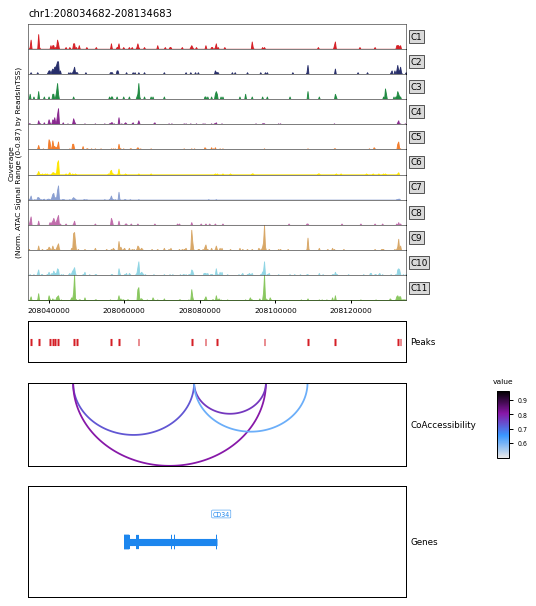

In [5]:
fig = epi.pl.plot_browser_track(
    adata, gene='CD34',
    fragments=fragments, group_by='Clusters',
    features=peaks, loops={'CoAccessibility': loops},
    gene_annotation=genes, exon_annotation=exons,
    show=False,
)
plt.show()

## Several marker genes

`plot_summary` selects which tracks to draw. Below we skip the loop track to
keep the figures compact.

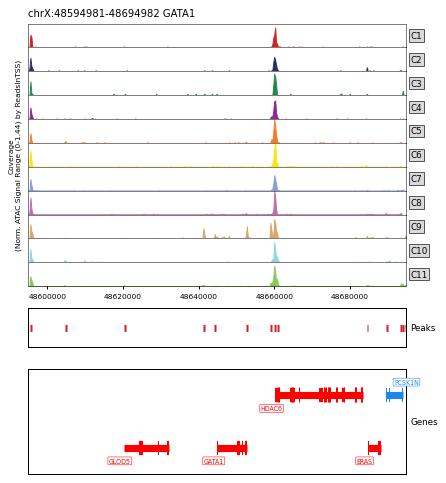

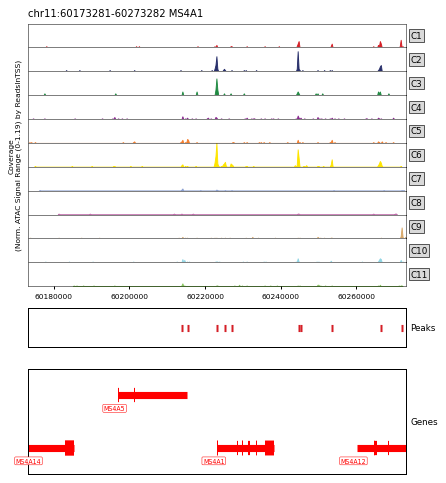

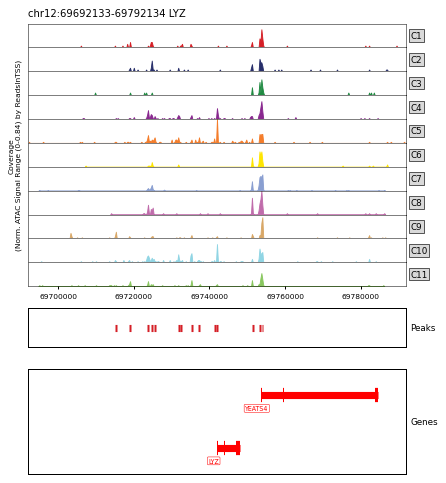

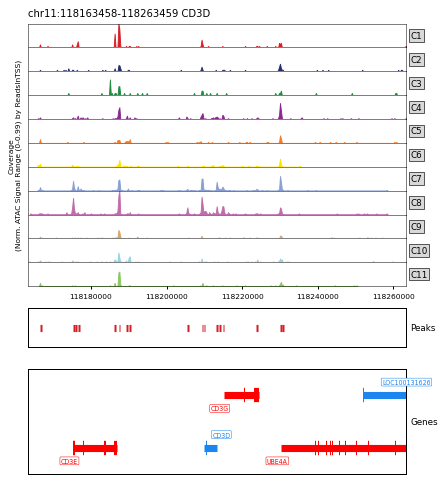

In [6]:
for g in ['GATA1', 'MS4A1', 'LYZ', 'CD3D']:
    fig = epi.pl.plot_browser_track(
        adata, gene=g, fragments=fragments,
        features=peaks, gene_annotation=genes, exon_annotation=exons,
        plot_summary=('bulkTrack', 'featureTrack', 'geneTrack'), sizes=(10, 1.5, 4),
        figsize=(6, 5.5), title=g, show=False,
    )
    plt.show()

## Subsets, explicit regions and highlights

* `use_groups` restricts the tracks to a subset of groups and sets their order.
* `region` takes `'chr:start-end'` or `(chrom, start, end)` in 1-based closed
  coordinates, the same as ArchR's GRanges.
* `highlight` shades intervals in every track.

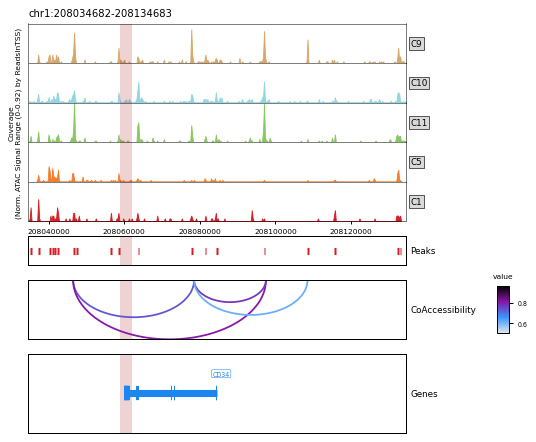

In [7]:
highlight = pd.DataFrame({'chrom': ['chr1'], 'start': [208_059_000], 'end': [208_062_000]})
fig = epi.pl.plot_browser_track(
    adata, region='chr1:208034683-208134683',
    fragments=fragments, use_groups=['C9', 'C10', 'C11', 'C5', 'C1'],
    features=peaks, loops={'CoAccessibility': loops},
    gene_annotation=genes, exon_annotation=exons, highlight=highlight,
    figsize=(6, 5), show=False,
)
plt.show()

## The underlying numbers

`epi.pl.browser_track_coverage` returns the long-format table that the
coverage track is drawn from. It mirrors ArchR's data frame row for row:
non-zero tiles, the zero-valued flanking tiles used by `geom_area`, and
ArchR's padding row past the last tile (`x = NaN`). The cells actually used
are in `.attrs['cells']`.

In [8]:
region = epi.pl._browser_track.gene_region(genes, 'MS4A1')
cov = epi.pl.browser_track_coverage(adata, region, fragments=fragments, group_by='Clusters')
print(region, len(cov), 'rows,', len(cov.attrs['cells']), 'cells')
cov.groupby('group')['y'].agg(['max', 'sum']).round(3)

('chr11', 60173282, 60273282) 774 rows, 4691 cells


,max,sum
group,,
C1,0.384,2.879
C10,0.201,2.050
C11,0.142,1.276
C2,1.007,4.657
C3,0.838,3.445
C4,0.175,2.661
C5,0.197,2.208
C6,1.832,7.704
C7,0.111,0.388


## Parity vs ArchR

Reference outputs come from ArchR 1.0.3 (R 4.4.3), run on the same project with
`tests/parity/browser_track/r_reference.R`, using `addArchRThreads(8)` and
`set.seed(1)` before each region. The gates were pre-registered in
`tests/parity/browser_track/MANIFEST.md`. `compare.py` re-computes every output
in Epione and compares it with ArchR's:

| Output | Gate |
|---|---|
| region from gene symbol | exact |
| coverage with ArchR's sampled cells injected | max \|Δ\| ≤ 1e-8 |
| coverage, free-running `seed=1, rng="archr"` | same cells, max \|Δ\| ≤ 1e-8 |
| clipped plot data (0.999 quantile) | max \|Δ\| ≤ 1e-8 |
| peaks / gene rows / palette | exact |
| loop arc geometry | max \|Δ\| ≤ 1e-6 |

In [9]:
import importlib.util
root = pathlib.Path(epi.__file__).resolve().parents[1]
spec = importlib.util.spec_from_file_location('bt_compare', root / 'tests/parity/browser_track/compare.py')
cmp = importlib.util.module_from_spec(spec); spec.loader.exec_module(cmp)
res = cmp.compare(ARCHR_REF, FIXTURE, FRAG_DIR)
print('palette identical:', res.pop('palette_identical'))
tab = pd.DataFrame(res).T[[
    'region_equal', 'n_rows_r', 'n_rows_py', 'coverage_max_abs', 'bulk_clipped_max_abs',
    'free_archr_rng_same_cells', 'free_archr_rng_max_abs',
    'features_identical', 'genes_identical', 'n_loops', 'loops_max_abs',
]]
num = ['coverage_max_abs', 'bulk_clipped_max_abs', 'free_archr_rng_max_abs', 'loops_max_abs']
tab = tab.astype({c: float for c in num})
tab.style.format('{:.1e}', subset=num)

palette identical: True


,region_equal,n_rows_r,n_rows_py,coverage_max_abs,bulk_clipped_max_abs,free_archr_rng_same_cells,free_archr_rng_max_abs,features_identical,genes_identical,n_loops,loops_max_abs
CD34,True,1555,1555,2.7e-15,5.0e-16,True,2.7e-15,True,True,4,5.4e-07
GATA1,True,944,944,4.9e-15,4.9e-15,True,4.9e-15,True,True,9,6.0e-08
MS4A1,True,774,774,2.4e-15,1.8e-15,True,2.4e-15,True,True,13,6.0e-08
LYZ,True,934,934,5.6e-16,5.6e-16,True,5.6e-16,True,True,4,6.0e-08
CD3D,True,1148,1148,4.2e-15,5.0e-16,True,4.2e-15,True,True,42,5.2e-07


Every class-1 gate passes. The largest coverage difference is about 5e-15,
which is double-precision rounding. Loop coordinates agree to the precision of
R's text export.

The `maxCells` subsampling is the only random step. The table below shows how
much the track depends on *which* cells are drawn. It compares ArchR's own
`set.seed(1)` and `set.seed(2)` draws, and five numpy-RNG draws against
ArchR's. This is why Epione ports R's RNG instead of only matching
distributions.

In [10]:
pd.DataFrame(res).T[['archr_seed1_vs_seed2_pearson', 'free_numpy_pearson_seeds_min_mean']]

,archr_seed1_vs_seed2_pearson,free_numpy_pearson_seeds_min_mean
CD34,0.925427,"[0.9163484431941717, 0.9298940405330848]"
GATA1,0.976956,"[0.9722827096924226, 0.9750908908771374]"
MS4A1,0.979932,"[0.9791242538922427, 0.9822039800404061]"
LYZ,0.941134,"[0.9220786779283654, 0.9305709544903177]"
CD3D,0.953639,"[0.9312167877219123, 0.946532810530317]"


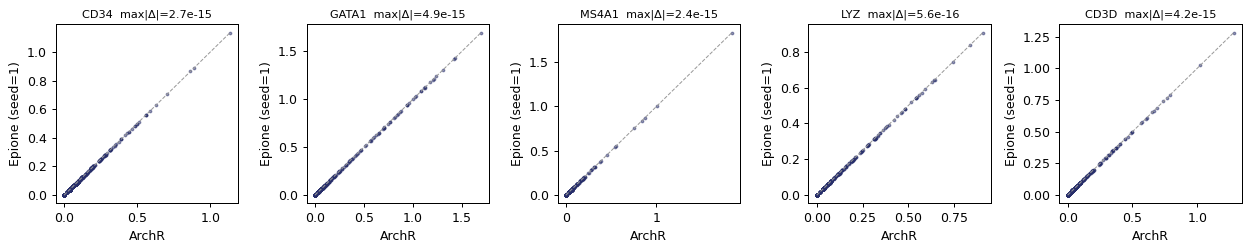

In [11]:
fig, axes = plt.subplots(1, 5, figsize=(14, 2.9))
for ax, g in zip(axes, cmp.GENES):
    raw = pd.read_csv(ARCHR_REF / f'{g}_raw.tsv', sep='\t')
    reg = epi.pl._browser_track.gene_region(genes, g)
    py = epi.pl.browser_track_coverage(adata, reg, fragments=fragments)
    ax.scatter(raw['y'], py['y'], s=4, alpha=0.5, color='#272E6A')
    m = max(raw['y'].max(), py['y'].max())
    ax.plot([0, m], [0, m], color='0.6', lw=0.8, ls='--')
    ax.set_title(f"{g}  max|Δ|={np.abs(raw['y'] - py['y']).max():.1e}", fontsize=9)
    ax.set_xlabel('ArchR'); ax.set_ylabel('Epione (seed=1)')
plt.tight_layout(); plt.show()

### Side by side

ArchR (`plotBrowserTrack`, left) and Epione (`plot_browser_track`, right) for
the same gene and the same settings.

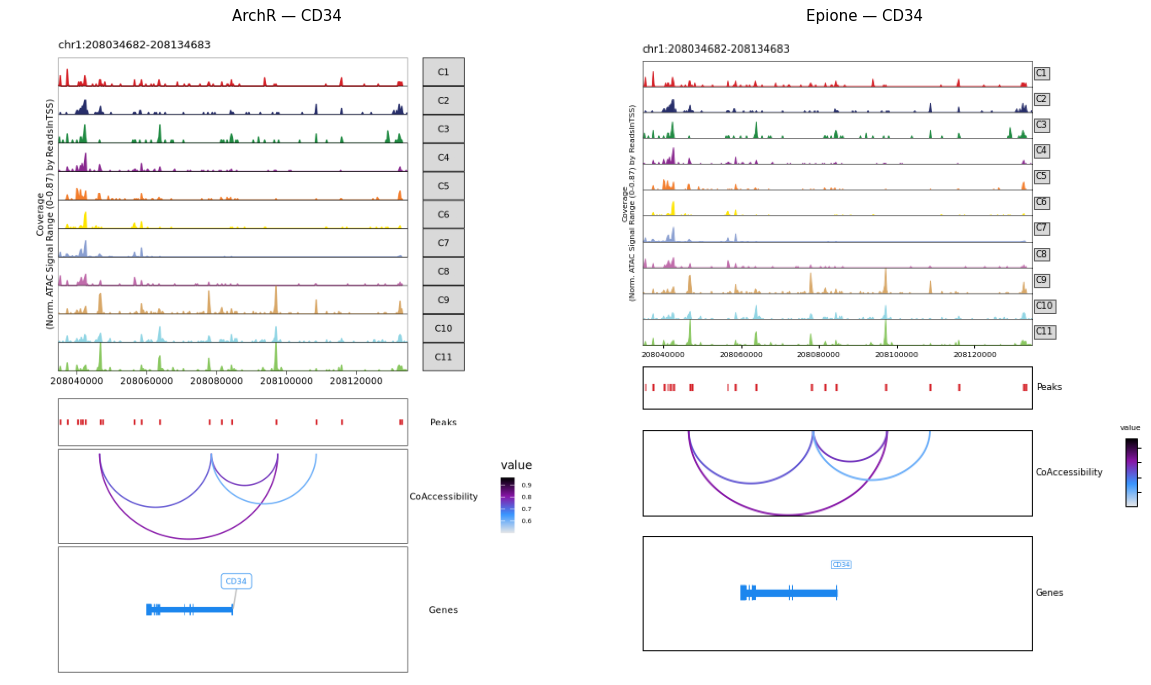

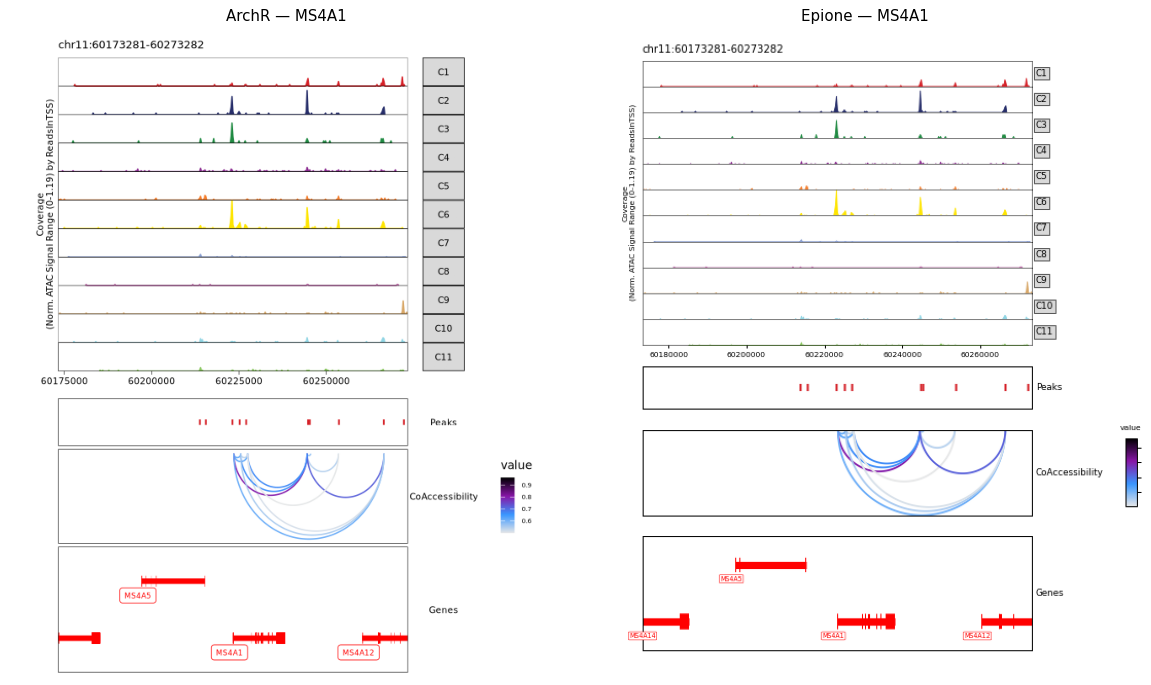

In [12]:
import matplotlib.image as mpimg
for g in ['CD34', 'MS4A1']:
    fig_e = epi.pl.plot_browser_track(
        adata, gene=g, fragments=fragments, features=peaks,
        loops={'CoAccessibility': loops}, gene_annotation=genes, exon_annotation=exons,
        show=False,
    )
    fig_e.canvas.draw()
    img_e = np.asarray(fig_e.canvas.buffer_rgba()); plt.close(fig_e)
    fig, axes = plt.subplots(1, 2, figsize=(13, 7.5))
    axes[0].imshow(mpimg.imread(ARCHR_REF / f'{g}_archr.png')); axes[0].set_title(f'ArchR — {g}')
    axes[1].imshow(img_e); axes[1].set_title(f'Epione — {g}')
    for ax in axes: ax.axis('off')
    plt.tight_layout(); plt.show()

## Notes

* The fragment files must be tabix-indexed (`epi.pp.ensure_tabix_index`).
  Fragment-file starts are 0-based; Epione adds 1, exactly as ArchR does when
  it builds Arrow files.
* `norm_method` accepts `ReadsInTSS` (default), `ReadsInPromoter`, `nFrags`
  (any of these needs the column in `adata.obs`), `nCells` and `None`.
* `ylim` uses ArchR's semantics: it gives *quantiles* of the signal, not
  absolute values.
* Set `rng="R"` to reproduce an ArchR session run with `threads = 1`, which
  keeps R's default Mersenne-Twister. Set `rng="numpy"` for a plain numpy
  draw.